# SAWNERGY V2 · From an MD trajectory to chosen measurements

**Lab demonstration using the bundled p53–DNA simulation**

SAWNERGY's existing workflow builds residue interaction networks, samples walks, learns residue
embeddings, and visualizes the results. V2 adds a configurable extraction workflow. We can define
measurements in CPPTRAJ, choose residues and source frames, and save arrays together with identities,
units, and the statistic each array represents.

We will calculate **RMSD**, **RMSF**, **electrostatic and vdW energies**, **hydrogen-bond counts**, and
**protein–DNA hydrogen-bond occupancy**. A radius-of-gyration example at the end demonstrates reusing
an earlier feature. Each calculation produces a SAWNERGY archive that we reopen for plotting.

The default run uses **50 saved frames**, **one CPPTRAJ thread**, and a few residues for pair
interactions. Saved outputs allow the notebook to be read and presented immediately.

## Start here

Install or upgrade to SAWNERGY 2.0 or later and install Jupyter in the Python environment you will use
for this notebook.

```bash
python -m pip install --upgrade "sawnergy>=2.0" jupyterlab
python -m jupyter lab
```

Select that environment's Python kernel. AmberTools provides CPPTRAJ. Activate its environment, put
`cpptraj` on `PATH`, or set `CPPTRAJ` to the executable path. The setup cell also shows where to supply
an explicit executable path.

Download `p53_DBD.prmtop`, `p53_DBD.nc`, and `p53_DBD.pdb` into a folder named
`example_MD_for_quick_start` beside this notebook. You can also use another data location by editing
`example` in the setup cell. [Download the example data](https://github.com/Yehor-Mishchyriak/SAWNERGY/tree/main/example_MD_for_quick_start)

Your working folder should contain the notebook and the data folder.

```text
analysis/
├── v2_feature_extraction.ipynb
└── example_MD_for_quick_start/
    ├── p53_DBD.prmtop
    ├── p53_DBD.nc
    └── p53_DBD.pdb
```

Run the cells from top to bottom. Generated archives are saved in `v2_outputs/` in your working folder.


In [1]:
from io import StringIO
from pathlib import Path
from tempfile import TemporaryDirectory
import os
import platform
from time import perf_counter
import warnings

import matplotlib.pyplot as plt
import numpy as np

import sawnergy
from sawnergy.rin.rin_util import locate_cpptraj, run_cpptraj
from sawnergy.sawnergy_util import ArrayStorage
from sawnergy.v2.traj_features.feature_extractor import ExtractionContext, FeatureExtractor, feature

notebook_started = perf_counter()
example = Path("example_MD_for_quick_start").expanduser().resolve()
topology_file = example / "p53_DBD.prmtop"
trajectory_file = example / "p53_DBD.nc"
for path in (topology_file, trajectory_file, example / "p53_DBD.pdb"):
    if not path.is_file():
        raise FileNotFoundError(f"Download {path.name} into {example}, or update the example path above.")
output_dir = Path("v2_outputs").resolve()
output_dir.mkdir(exist_ok=True)
cpptraj_path = locate_cpptraj()  # Or assign an explicit executable path here.

# Filter the repeated ZIP metadata warning produced by the current Zarr writer.
warnings.filterwarnings("ignore", message="Duplicate name: 'zarr.json'", category=UserWarning)
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (10, 4.2), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 13, "savefig.bbox": "tight",
})
BLUE, TEAL, ORANGE = "#335c96", "#16857b", "#cf7832"
print("SAWNERGY", sawnergy.__version__, "| Python", platform.python_version())
print(run_cpptraj(str(cpptraj_path), argv=["--version"]).strip())

SAWNERGY 1.1.6 | Python 3.12.1
CPPTRAJ: Version V6.18.1 (AmberTools)


## The system and the residue labels

The example contains **194 protein residues**, **two DNA strands of 21 nucleotides each**, and zinc.
The trajectory contains 1,000 saved frames. Simulation credit belongs to **Sean Stetson**.

| Molecule in this topology | Residue IDs |
| --- | --- |
| Protein and zinc | Protein `1–194`, zinc `195` |
| DNA strand 1 | `196–216` |
| DNA strand 2 | `217–237` |

Every residue label below uses **topology numbering**. For example, ARG 185 means residue 185 in this
file. The structural overview uses the supplied PDB reference structure.

The dataset notes give a 1 ns saving interval, while the NetCDF time values advance by 1 ps.
Plots therefore use **source frame numbers** until the physical timing is clarified.

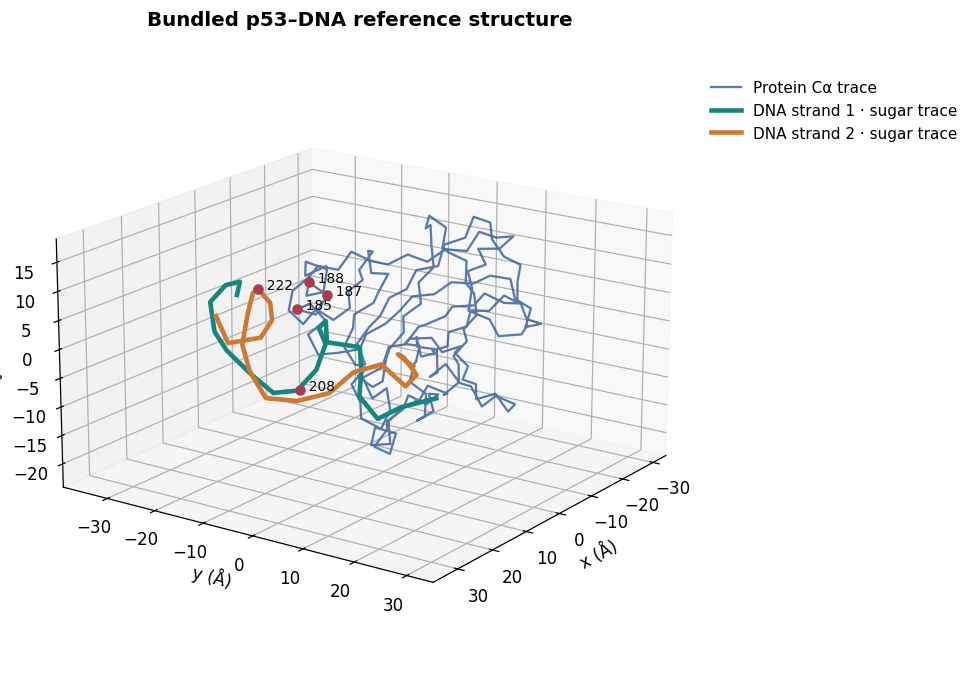

In [2]:
residue_names = {}
pdb_coordinates = {}
for line in (example / "p53_DBD.pdb").read_text().splitlines():
    if line.startswith(("ATOM  ", "HETATM")):
        residue = int(line[22:26])
        atom = line[12:16].strip()
        residue_names[residue] = line[17:20].strip()
        pdb_coordinates[residue, atom] = np.array([
            float(line[30:38]), float(line[38:46]), float(line[46:54]),
        ])

protein_ids = np.arange(1, 195)
protein_ca = np.array([pdb_coordinates[int(residue), "CA"] for residue in protein_ids])
fig = plt.figure(figsize=(10.5, 6.2), layout="constrained")
ax = fig.add_subplot(projection="3d")
ax.plot(*protein_ca.T, color=BLUE, linewidth=1.5, alpha=0.8, label="Protein Cα trace")
all_coordinates = [protein_ca]
for ids, color, label in (
    (range(196, 217), TEAL, "DNA strand 1 · sugar trace"),
    (range(217, 238), ORANGE, "DNA strand 2 · sugar trace"),
):
    coordinates = np.array([pdb_coordinates[residue, "C1'"] for residue in ids])
    ax.plot(*coordinates.T, color=color, linewidth=3, label=label)
    all_coordinates.append(coordinates)
for residue in (185, 187, 188, 208, 222):
    atom = "CA" if residue < 195 else "C1'"
    coordinate = pdb_coordinates[residue, atom]
    ax.scatter(*coordinate, color="#ad3b50", s=35, depthshade=False)
    ax.text(*coordinate, f"  {residue}", fontsize=9)
ax.set(xlabel="x (Å)", ylabel="y (Å)", zlabel="z (Å)",
       title="Bundled p53–DNA reference structure")
ax.set_box_aspect(np.ptp(np.vstack(all_coordinates), axis=0))
ax.view_init(elev=18, azim=35)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 0.95), frameon=False, fontsize=10)
plt.show()

## Choose the measurement scale

A **frame** is one saved structure. A **window** groups selected frames into one result. With 50 frames
and windows of 10, we obtain five window results. A **batch** is how many windows a feature receives
in a single call. Batch size controls working memory and should preserve the statistic.

We use the whole protein for RMSD and RMSF, three protein residues for the general hydrogen-bond
example, and five interface residues for interaction examples. Each selected residue contributes all
its atoms. Increase the frame range gradually when exploring the notebook on a laptop.

In [3]:
FRAME_RANGE = (1, 50)  # Inclusive source frames. Edit here to explore a longer excerpt.
WINDOW_SIZE = 10
BATCH_SIZE = 2

inputs = dict(
    topology_file=topology_file, trajectory_file=trajectory_file,
    cpptraj_path=cpptraj_path, frame_range=FRAME_RANGE, frame_stride=1,
    window_size=WINDOW_SIZE, batch_size=BATCH_SIZE,
)
protein_selection = {1: protein_ids.tolist()}
protein_inputs = dict(inputs, selection=protein_selection)
residue_count = len(protein_ids)
pair_selection = {1: [185, 187, 188], 2: [208], 3: [222]}
pair_inputs = dict(inputs, selection=pair_selection)
hbond_inputs = dict(inputs, selection={1: [20, 23, 26]})

print("Source frames", FRAME_RANGE, "| Frames per window", WINDOW_SIZE,
      "| Windows per batch", BATCH_SIZE)
print("Protein RMSD/RMSF", residue_count, "residues")
print("Interface residues", pair_selection)

Source frames (1, 50) | Frames per window 10 | Windows per batch 2
Protein RMSD/RMSF 194 residues
Interface residues {1: [185, 187, 188], 2: [208], 3: [222]}


## How a measurement becomes a feature

Create a subclass of `FeatureExtractor` and mark each measurement method with `@feature(...)`.
Python supplies `self`, the extractor instance. SAWNERGY supplies `ctx`, containing the selected
residues, atoms, frames, source paths, and CPPTRAJ executable. It returns a NumPy array. `featurize()` checks the declared shape, numeric type, and finite
values, then writes the results and metadata to a compressed archive.

| Declaration | Meaning in these examples |
| --- | --- |
| `kind="global"` | A scalar or fixed-size vector describing the selected system |
| `kind="pairwise"` | A residue × residue matrix, with both axes in `ctx.residue_ids` order |
| `scope="window"` | One sample for each selected-frame window |
| `scope="trajectory"` | One result across all selected frames |
| `units`, `statistic` | Saved descriptions of what the numbers mean |

The next helper cell is shared with the documentation. It passes the selected mask and frames to
CPPTRAJ and reads its numeric output. In script strings, `{mask}`, `{trajectory}`, and `{directory}`
are filled in for the current call. CPPTRAJ subprocesses use one OpenMP thread for this laptop demo.

In [4]:
def cpptraj_files(ctx, frames, commands):
    """Run a CPPTRAJ script for selected frames and return its .dat file contents."""
    first, last = frames[0], frames[-1]
    stride = frames[1] - first if len(frames) > 1 else 1
    with TemporaryDirectory(prefix="sawnergy_example_") as directory:
        directory = Path(directory)
        topology = directory / ("topology" + ctx.topology_file.suffix)
        trajectory = directory / ("trajectory" + ctx.trajectory_file.suffix)
        topology.symlink_to(ctx.topology_file)
        trajectory.symlink_to(ctx.trajectory_file)
        script = (
            f'parm "{topology}"\n'
            f'trajin "{trajectory}" {first} {last} {stride}\n'
            + commands.format(
                mask=ctx.selection_mask, trajectory=trajectory, directory=directory,
            )
        )
        run_cpptraj(str(ctx.cpptraj), script=script,
                    env={**os.environ, "OMP_NUM_THREADS": "1"})
        return {path.name: path.read_text() for path in directory.glob("*.dat")}


def table(text):
    """Read a numeric CPPTRAJ table, skipping its comment header."""
    return np.loadtxt(StringIO(text), comments="#", ndmin=2)


def frame_values(text, frames):
    """Read one measurement per processed frame and check the row order."""
    data = table(text)
    if data.shape != (len(frames), 2):
        raise ValueError("Expected one measurement per selected frame.")
    if not np.array_equal(data[:, 0], np.arange(1, len(frames) + 1)):
        raise ValueError("Unexpected CPPTRAJ output frame order.")
    return data[:, 1]


def window_means(values, windows):
    """Average per-frame measurements within each window, including a short last window."""
    means = []
    start = 0
    for window in windows:
        stop = start + len(window)
        means.append(values[start:stop].mean())
        start = stop
    return np.asarray(means, dtype="float64")

In [5]:
def load_archive(path):
    """Read this small demonstration archive and its saved identities."""
    with ArrayStorage(path, mode="r") as archive:
        declarations = archive.get_attr("features")
        return dict(
            features={entry["name"]: archive.read(entry["block"]) for entry in declarations},
            declarations=declarations,
            residue_ids=archive.read("residue_ids"),
            frame_ids=archive.read("frame_ids"),
            window_offsets=archive.read("window_offsets"),
        )


def window_centers(result):
    """Locate each window at its mean source-frame number."""
    frames, offsets = result["frame_ids"], result["window_offsets"]
    return np.array([frames[start:stop].mean() for start, stop in zip(offsets[:-1], offsets[1:])])


def residue_labels(identities):
    """Label residue identities using names from the supplied PDB."""
    return [f"{residue_names[int(residue)]} {residue}" for molecule, residue in identities]


def heatmap(ax, values, rows, columns, title, units, cmap="viridis", vmin=None, vmax=None):
    """Draw a labeled matrix with numeric entries and a color scale."""
    image = ax.imshow(values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    ax.set(xticks=np.arange(len(columns)), xticklabels=columns,
           yticks=np.arange(len(rows)), yticklabels=rows, title=title)
    ax.tick_params(axis="x", labelrotation=45)
    for row in range(len(rows)):
        for column in range(len(columns)):
            rgba = image.cmap(image.norm(values[row, column]))
            luminance = 0.2126 * rgba[0] + 0.7152 * rgba[1] + 0.0722 * rgba[2]
            ax.text(column, row, f"{values[row, column]:.2f}", ha="center", va="center",
                    color="black" if luminance > 0.55 else "white", fontsize=10)
    ax.figure.colorbar(image, ax=ax, shrink=0.85, label=units)
    return image

## 1. RMSD · How far has the protein moved from the reference?

CPPTRAJ fits all selected protein atoms to source frame 1 by translation and rotation, then measures
RMSD in angstroms. The atom weights are equal. That reference stays fixed across batches.

$$\mathrm{RMSD}(t)=\sqrt{\frac{1}{A}\sum_{a=1}^{A}
\left\|\mathbf{x}^{\mathrm{fit}}_a(t)-\mathbf{x}_a(1)\right\|^2}.$$

We save both per-frame values and 10-frame means to see the effect of choosing a window size.
The gray curve shows individual selected structures and the blue curve shows their window means.
[CPPTRAJ RMSD](https://amberhub.chpc.utah.edu/rmsd/)

In [6]:
class RMSDFeatures(FeatureExtractor):
    @feature(
        kind="global", scope="window", shape=(), dtype="float64",
        units="angstrom", statistic="mean best-fit all-atom RMSD to source frame 1",
    )
    def rmsd(self, ctx: ExtractionContext):
        """Average CPPTRAJ RMSD values within each window."""
        files = cpptraj_files(ctx, ctx.frame_ids, """
reference "{trajectory}" 1 [Start]
rms RMSD {mask} ref [Start] out "{directory}/rmsd.dat" prec 18.10
run
""")
        values = frame_values(files["rmsd.dat"], ctx.frame_ids)
        return window_means(values, ctx.windows)

In [7]:
rmsd_started = perf_counter()
rmsd_path = RMSDFeatures().featurize(
    **protein_inputs, output_path=output_dir / "protein_rmsd_windows.zip",
)
per_frame_inputs = dict(protein_inputs, window_size=1, batch_size=25)
rmsd_frame_path = RMSDFeatures().featurize(
    **per_frame_inputs, output_path=output_dir / "protein_rmsd_frames.zip",
)
rmsd = load_archive(rmsd_path)
rmsd_frames = load_archive(rmsd_frame_path)
print("RMSD samples", len(rmsd_frames["features"]["rmsd"]),
      "per frame →", len(rmsd["features"]["rmsd"]), "window means")
print(f"RMSD extraction took {perf_counter() - rmsd_started:.2f} s")

RMSD samples 50 per frame → 5 window means
RMSD extraction took 0.86 s


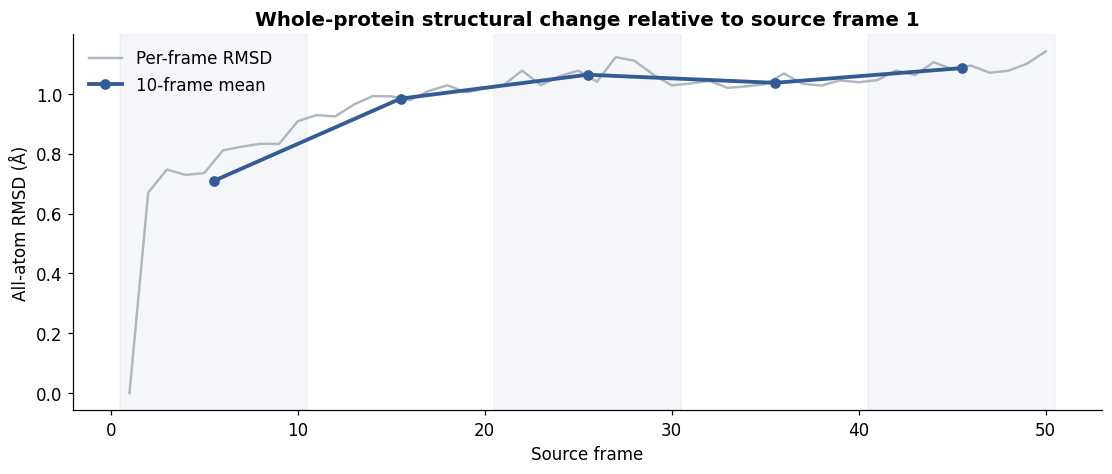

In [8]:
fig, ax = plt.subplots(layout="constrained")
ax.plot(rmsd_frames["frame_ids"], rmsd_frames["features"]["rmsd"],
        color="#aeb7c1", linewidth=1.6, label="Per-frame RMSD")
ax.plot(window_centers(rmsd), rmsd["features"]["rmsd"], "o-", color=BLUE,
        linewidth=2.5, label=f"{WINDOW_SIZE}-frame mean")
for index, (start, stop) in enumerate(zip(rmsd["window_offsets"][:-1], rmsd["window_offsets"][1:])):
    if index % 2 == 0:
        frames = rmsd["frame_ids"][start:stop]
        ax.axvspan(frames[0] - 0.5, frames[-1] + 0.5, color=BLUE, alpha=0.05)
ax.set(xlabel="Source frame", ylabel="All-atom RMSD (Å)",
       title="Whole-protein structural change relative to source frame 1")
ax.legend(frameon=False)
plt.show()

Window means retain changes on the chosen scale and average over variation within each window.
Setting `window_size=1` retains every selected frame. The archive records which source frames
contribute to each mean, including a final short window.

## 2. RMSF · Where is the protein flexible?

CPPTRAJ first fits to the first selected frame and builds an average of the selected coordinates.
It then fits to that average and calculates atomic fluctuations across the selected excerpt.

$$\mathrm{RMSF}_a=\sqrt{\left\langle
\left\|\mathbf{x}_a-\left\langle\mathbf{x}_a\right\rangle\right\|^2
\right\rangle}.$$

`byres` reports the mass-weighted mean of these atomic RMSF values within each residue.
The saved vector has one entry per protein residue in topology order. This calculation uses all
selected frames together. [CPPTRAJ RMSF](https://amberhub.chpc.utah.edu/atomicfluct-rmsf/)

In [9]:
class RMSFFeatures(FeatureExtractor):
    @feature(
        kind="global", scope="trajectory", shape=(residue_count,), dtype="float64",
        units="angstrom", statistic="per-residue atomic RMSF after fitting to average structure",
    )
    def rmsf(self, ctx: ExtractionContext):
        """Calculate residue RMSF across all selected frames in a single CPPTRAJ call."""
        files = cpptraj_files(ctx, ctx.frame_ids, """
rms {mask} first
average {mask} crdset Mean
run
rms {mask} ref Mean @*
atomicfluct Fluct {mask} byres out "{directory}/rmsf.dat" prec 18.10
run
""")
        data = table(files["rmsf.dat"])
        expected_ids = np.asarray([residue for molecule, residue in ctx.residue_ids])
        if data.shape != (len(expected_ids), 2) or not np.array_equal(data[:, 0], expected_ids):
            raise ValueError("RMSF output does not match the selected residue order.")
        return data[:, 1]

In [10]:
rmsf_started = perf_counter()
rmsf_path = RMSFFeatures().featurize(**protein_inputs, output_path=output_dir / "protein_rmsf.zip")
rmsf = load_archive(rmsf_path)
rmsf_values = rmsf["features"]["rmsf"][0]
print("Residues measured", len(rmsf_values))
print(f"RMSF extraction took {perf_counter() - rmsf_started:.2f} s")

Residues measured 194
RMSF extraction took 0.30 s


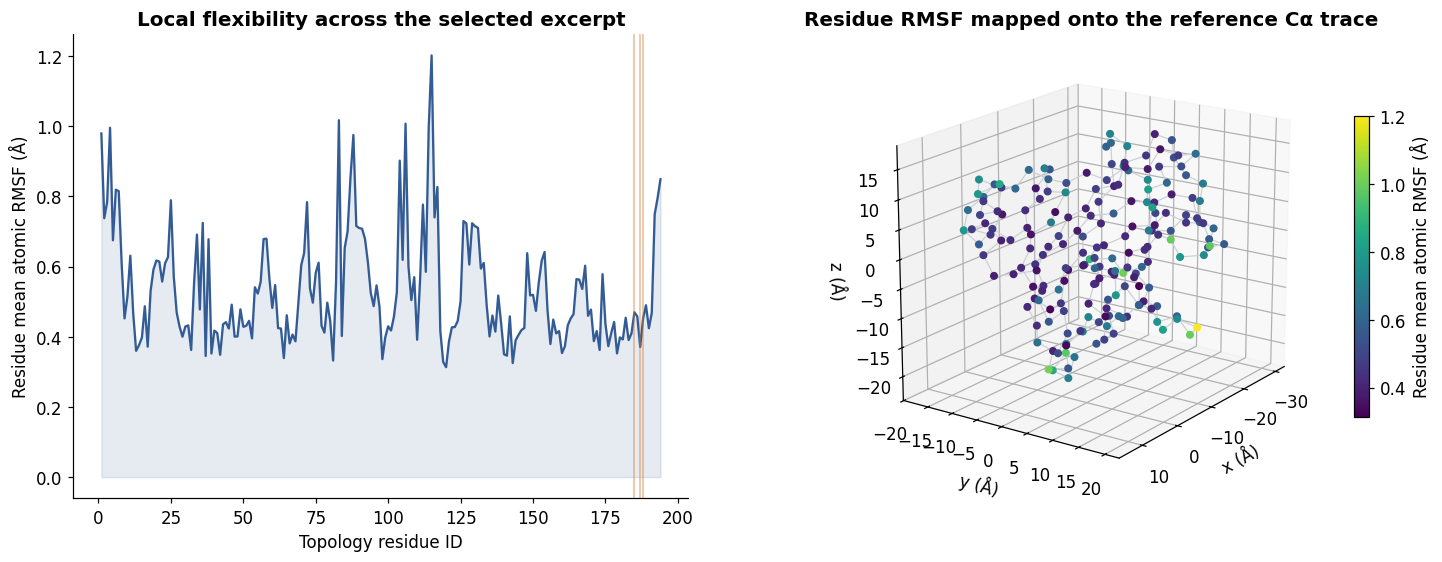

In [11]:
fig = plt.figure(figsize=(13, 5), layout="constrained")
ax = fig.add_subplot(1, 2, 1)
residue_numbers = rmsf["residue_ids"][:, 1]
ax.plot(residue_numbers, rmsf_values, color=BLUE, linewidth=1.5)
ax.fill_between(residue_numbers, 0, rmsf_values, color=BLUE, alpha=0.12)
for residue in (185, 187, 188):
    ax.axvline(residue, color=ORANGE, alpha=0.5, linewidth=1)
ax.set(xlabel="Topology residue ID", ylabel="Residue mean atomic RMSF (Å)",
       title="Local flexibility across the selected excerpt")
structure_ax = fig.add_subplot(1, 2, 2, projection="3d")
structure_ax.plot(*protein_ca.T, color="#ccd0d5", linewidth=0.8)
scatter = structure_ax.scatter(*protein_ca.T, c=rmsf_values, cmap="viridis", s=18, depthshade=False)
structure_ax.set(title="Residue RMSF mapped onto the reference Cα trace",
                 xlabel="x (Å)", ylabel="y (Å)", zlabel="z (Å)")
structure_ax.set_box_aspect(np.ptp(protein_ca, axis=0))
structure_ax.view_init(elev=18, azim=35)
fig.colorbar(scatter, ax=structure_ax, shrink=0.65, label="Residue mean atomic RMSF (Å)")
plt.show()

Higher values identify residues with larger atomic fluctuations after fitting. The structural panel
uses each residue's Cα position to locate its value on the supplied reference structure.
Orange lines mark the protein residues used in the later interface examples.

## 3. Electrostatic and vdW energies · Which residue pairs interact?

Each feature uses CPPTRAJ's direct, nonperiodic `pairwise` calculation with topology exclusions.
It averages atomic energies in each window, then sums contributions between selected residue pairs.
We save electrostatic and van der Waals components separately, retaining their signs, in kcal/mol.
The diagonal is set to zero because these plots show interactions between different residues.

For a component $E$, the displayed entry is
$$\overline{E}_{rs}=\frac{1}{|\mathcal{W}|}\sum_{t\in\mathcal{W}}
\sum_{a\in r}\sum_{b\in s}E_{ab}(t),\qquad r\ne s,$$
with the topology exclusions applied by CPPTRAJ.

Negative entries lower the chosen pair-energy component relative to its zero at infinite separation.
Positive entries raise it. These component energies describe the chosen direct interactions. Binding free energy also depends
on solvent, entropy, and the rest of the system. [CPPTRAJ pairwise energies](https://amberhub.chpc.utah.edu/pairwise/)

In [12]:
class EnergyFeatures(FeatureExtractor):
    def _mean_energy(self, ctx, aspect):
        """Sum a window-averaged atomic energy matrix into residue-pair energies."""
        counts = [len(atoms) for atoms in ctx.atom_ids]
        membership = np.repeat(np.arange(len(counts)), counts)
        projection = np.eye(len(counts))[membership]
        matrices = []
        for window in ctx.windows:
            commands = """
pairwise PW {mask} cuteelec 0 cutevdw 0
run
writedata "{directory}/energy.dat" PW[ASPECT] square2d noheader prec 18.10
""".replace("ASPECT", aspect)
            files = cpptraj_files(ctx, window, commands)
            atomic = table(files["energy.dat"])
            if atomic.shape != (len(membership), len(membership)):
                raise ValueError("Energy output does not match the selected atoms.")
            residues = projection.T @ atomic @ projection
            np.fill_diagonal(residues, 0.0)
            matrices.append(residues)
        return np.asarray(matrices, dtype="float64")

    @feature(
        kind="pairwise", scope="window", shape=("N", "N"), dtype="float64",
        units="kcal/mol", statistic="mean signed residue-pair electrostatic energy",
    )
    def electrostatics(self, ctx: ExtractionContext):
        """Return the electrostatic energy matrix for each window."""
        return self._mean_energy(ctx, "EMAP")

    @feature(
        kind="pairwise", scope="window", shape=("N", "N"), dtype="float64",
        units="kcal/mol", statistic="mean signed residue-pair van der Waals energy",
    )
    def vdw(self, ctx: ExtractionContext):
        """Return the van der Waals energy matrix for each window."""
        return self._mean_energy(ctx, "VMAP")

In [13]:
energy_started = perf_counter()
energy_path = EnergyFeatures().featurize(**pair_inputs, output_path=output_dir / "interface_energies.zip")
energies = load_archive(energy_path)
print("Energy array shape", energies["features"]["electrostatics"].shape,
      "= windows × selected residues × selected residues")
print(f"Energy extraction took {perf_counter() - energy_started:.2f} s")

Energy array shape (5, 5, 5) = windows × selected residues × selected residues
Energy extraction took 1.07 s


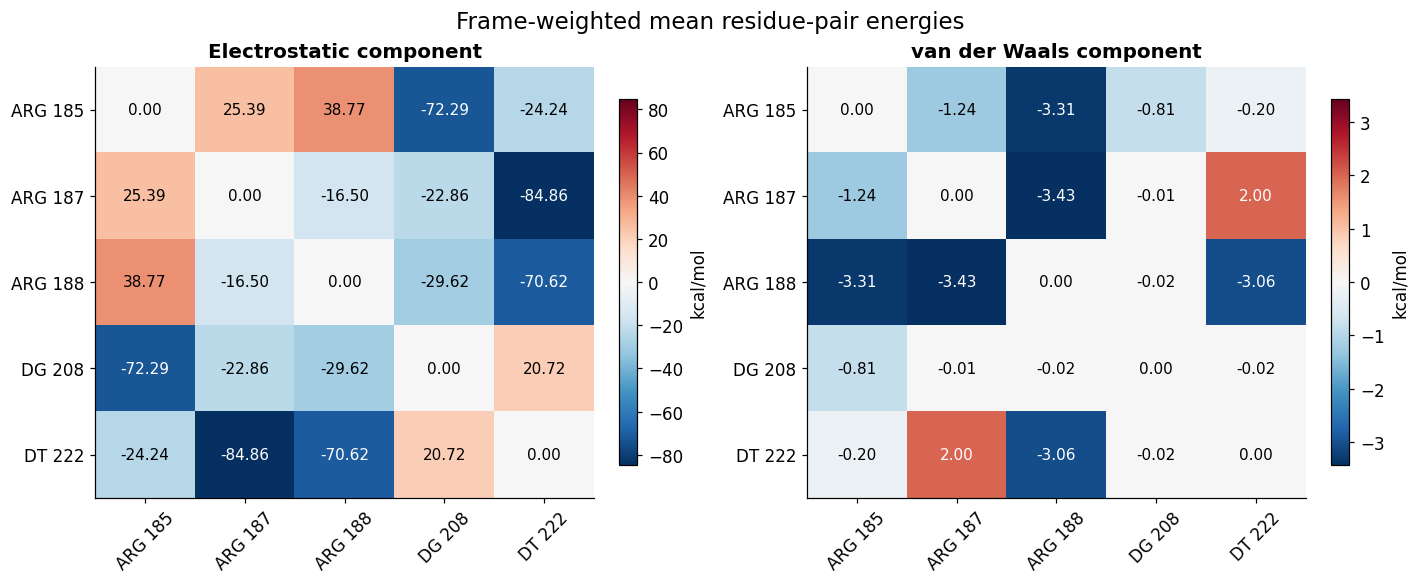

In [14]:
window_weights = np.diff(energies["window_offsets"])
energy_labels = residue_labels(energies["residue_ids"])
fig, axes = plt.subplots(1, 2, figsize=(12.8, 5.2), layout="constrained")
for ax, name, title in zip(axes, ("electrostatics", "vdw"), ("Electrostatic component", "van der Waals component")):
    mean = np.average(energies["features"][name], axis=0, weights=window_weights)
    limit = max(float(np.abs(mean).max()), 1e-12)
    heatmap(ax, mean, energy_labels, energy_labels, title, "kcal/mol",
            cmap="RdBu_r", vmin=-limit, vmax=limit)
fig.suptitle("Frame-weighted mean residue-pair energies", fontsize=15)
plt.show()

Each heatmap has its own scale so both components remain visible. The frame-weighted average gives
each selected frame equal weight, including when the final window is shorter. The residue identities
come from the archive, preserving the row and column meaning after extraction.

## 4. Hydrogen bonds · How many bonds connect a residue pair?

CPPTRAJ detects donor–acceptor contacts with distance cutoff 3 Å and acceptor–hydrogen–donor angle
cutoff 135°, using its automatic donor/acceptor search. We combine both donor directions and average
the bond count within each window. Distances use the coordinates as stored.

A residue pair can form several hydrogen bonds simultaneously, so its mean count can exceed one.
The example requests raw residue counts and divides by the actual window length. With the locally
tested CPPTRAJ V6.18.1, `uuresmatrixnorm frames` produced an additional division by the frame count.
[CPPTRAJ hydrogen bonds](https://amberhub.chpc.utah.edu/hbond/)

In [15]:
class HbondFeatures(FeatureExtractor):
    @feature(
        kind="pairwise", scope="window", shape=("N", "N"), dtype="float64",
        units="1", statistic="mean number of hydrogen bonds per residue pair, both directions",
    )
    def mean_hbonds(self, ctx: ExtractionContext):
        """Average raw CPPTRAJ residue-pair bond counts over each window."""
        indices = np.asarray([residue - 1 for molecule, residue in ctx.residue_ids])
        matrices = []
        for window in ctx.windows:
            files = cpptraj_files(ctx, window, """
hbond HB {mask} dist 3.0 angle 135 uuresmatrix uuresmatrixnorm none
run
writedata "{directory}/hbonds.dat" HB[UUresmat] square2d noheader prec 18.10
""")
            raw = table(files["hbonds.dat"])
            if raw.shape[0] != raw.shape[1] or raw.shape[0] <= indices.max():
                raise ValueError("Hydrogen-bond matrix does not cover the selected residues.")
            means = raw[np.ix_(indices, indices)] / len(window)
            np.fill_diagonal(means, 0.0)
            matrices.append(means)
        return np.asarray(matrices, dtype="float64")

In [16]:
hbond_started = perf_counter()
hbond_path = HbondFeatures().featurize(**hbond_inputs, output_path=output_dir / "protein_hbond_counts.zip")
hbonds = load_archive(hbond_path)
print("Hydrogen-bond array shape", hbonds["features"]["mean_hbonds"].shape)
print(f"Hydrogen-bond extraction took {perf_counter() - hbond_started:.2f} s")

Hydrogen-bond array shape (5, 3, 3)
Hydrogen-bond extraction took 0.69 s


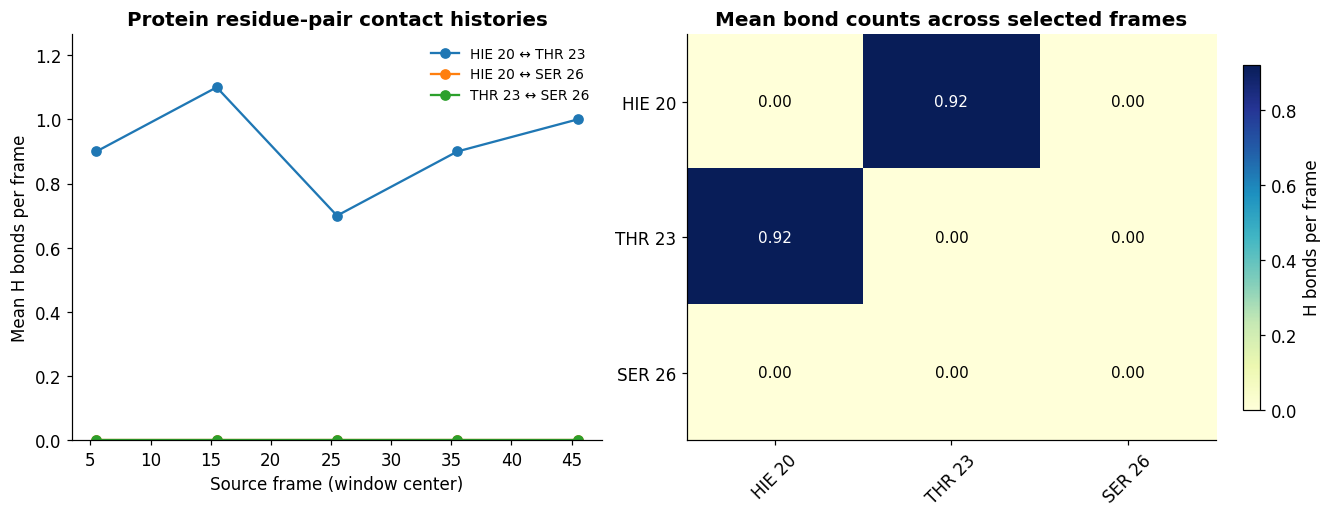

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout="constrained")
labels = residue_labels(hbonds["residue_ids"])
values = hbonds["features"]["mean_hbonds"]
for row in range(len(labels)):
    for column in range(row + 1, len(labels)):
        axes[0].plot(window_centers(hbonds), values[:, row, column], "o-",
                     label=f"{labels[row]} ↔ {labels[column]}")
axes[0].set(xlabel="Source frame (window center)", ylabel="Mean H bonds per frame",
            title="Protein residue-pair contact histories", ylim=(0, max(1.1, float(values.max()) * 1.15)))
axes[0].legend(frameon=False, fontsize=9)
mean = np.average(values, axis=0, weights=np.diff(hbonds["window_offsets"]))
heatmap(axes[1], mean, labels, labels, "Mean bond counts across selected frames",
        "H bonds per frame", cmap="YlGnBu", vmin=0)
plt.show()

## 5. Protein–DNA hydrogen bonds · How persistent are interface contacts?

We examine protein ARG 185, ARG 187, ARG 188 and DNA DG 208, DT 222, using topology numbering.
For each protein–DNA pair, CPPTRAJ supplies the number of simultaneous hydrogen bonds in every
selected frame. We save two window statistics.

$$\text{mean count}=\frac{1}{F}\sum_t C_{rs}(t),\qquad
\text{occupancy}=\frac{1}{F}\sum_t\mathbf{1}\{C_{rs}(t)>0\}.$$

For counts `[0, 2, 1, 1]`, the mean is $4/4=1.0$ and occupancy is $3/4=0.75$.
Mean count measures multiplicity, while occupancy measures how often any bond is present.
The same geometric criteria are used here. `nointramol` restricts each two-residue search to bonds
between the protein and DNA molecules.

In [18]:
class ProteinDNAFeatures(FeatureExtractor):
    def _counts(self, ctx, window):
        """Read per-frame counts for every selected protein–DNA residue pair."""
        pairs = [
            (i, j, protein, dna)
            for i, (protein_molecule, protein) in enumerate(ctx.residue_ids)
            for j, (dna_molecule, dna) in enumerate(ctx.residue_ids)
            if protein_molecule == 1 and dna_molecule in (2, 3)
        ]
        if not pairs:
            raise ValueError("Select protein residues and DNA residues from the bundled system.")
        commands = []
        for i, j, protein, dna in pairs:
            commands.append(
                f'hbond HB_{i}_{j} :{protein},{dna} nointramol dist 3.0 angle 135 '
                f'out "{{directory}}/pair_{i}_{j}.dat"'
            )
        files = cpptraj_files(ctx, window, "\n".join(commands + ["run"]))
        counts = np.zeros((len(window), len(ctx.residue_ids), len(ctx.residue_ids)))
        for i, j, protein, dna in pairs:
            values = frame_values(files[f"pair_{i}_{j}.dat"], window)
            counts[:, i, j] = values
            counts[:, j, i] = values
        return counts

    @feature(
        kind="pairwise", scope="window", shape=("N", "N"), dtype="float64",
        units="1", statistic="mean protein-DNA hydrogen-bond count per residue pair",
    )
    def mean_hbonds(self, ctx: ExtractionContext):
        """Return mean interface bond counts in each window."""
        return np.asarray([self._counts(ctx, window).mean(axis=0) for window in ctx.windows])

    @feature(
        kind="pairwise", scope="window", shape=("N", "N"), dtype="float64",
        units="1", statistic="fraction of frames with any protein-DNA hydrogen bond per residue pair",
    )
    def hbond_occupancy(self, ctx: ExtractionContext):
        """Return interface contact occupancy in each window."""
        return np.asarray([(self._counts(ctx, window) > 0).mean(axis=0) for window in ctx.windows])

### Add a summary using an earlier feature

The next subclass inherits both interface features and adds the total mean number of selected
protein–DNA hydrogen bonds. `requires=("mean_hbonds",)` makes the completed window matrices available
through `ctx.dependencies`. Summing one triangle counts each pair once.

This is the extension pattern for a new measurement. Declare what it returns, supply its calculation,
and run the same extraction interface.

In [19]:
class InterfaceSummary(ProteinDNAFeatures):
    @feature(
        kind="global", scope="window", shape=(), dtype="float64", units="1",
        statistic="mean total hydrogen-bond count across selected protein-DNA pairs",
        requires=("mean_hbonds",),
    )
    def total_interface_hbonds(self, ctx: ExtractionContext):
        """Count each unordered residue pair once in the matching window batch."""
        means = ctx.dependencies["mean_hbonds"].read()
        return np.triu(means, k=1).sum(axis=(1, 2))


interface_started = perf_counter()
interface_path = InterfaceSummary().featurize(
    **pair_inputs, output_path=output_dir / "protein_dna_hbonds.zip",
)
interface = load_archive(interface_path)
print("Features saved", list(interface["features"]))
print(f"Protein-DNA extraction took {perf_counter() - interface_started:.2f} s")

Features saved ['mean_hbonds', 'hbond_occupancy', 'total_interface_hbonds']
Protein-DNA extraction took 1.13 s


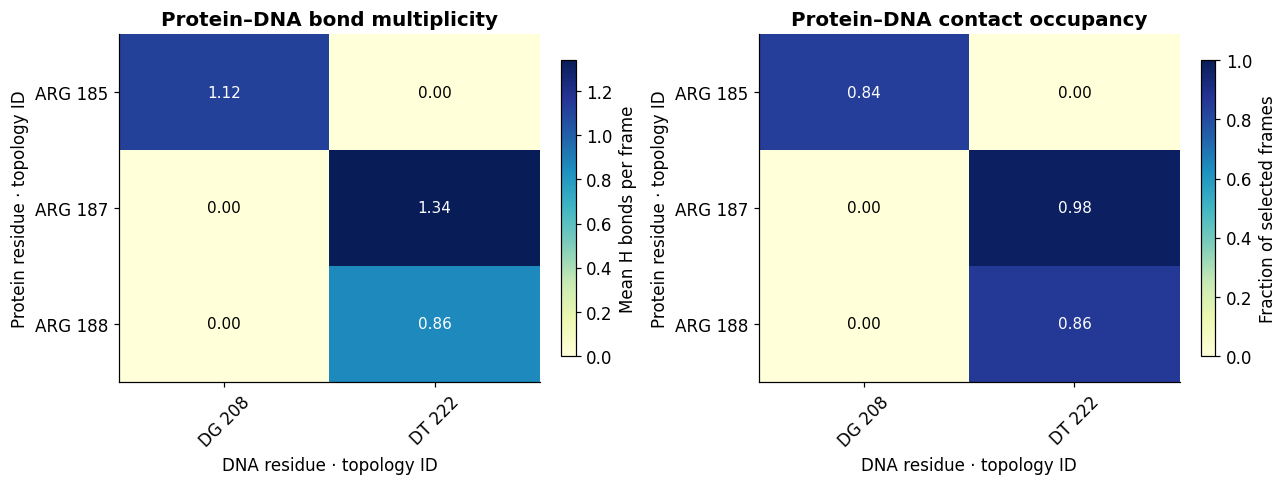

In [20]:
identities = interface["residue_ids"]
protein_positions = np.flatnonzero(identities[:, 0] == 1)
dna_positions = np.flatnonzero(np.isin(identities[:, 0], [2, 3]))
protein_labels = residue_labels(identities[protein_positions])
dna_labels = residue_labels(identities[dna_positions])
weights = np.diff(interface["window_offsets"])
mean_counts = np.average(interface["features"]["mean_hbonds"], axis=0, weights=weights)
mean_occupancy = np.average(interface["features"]["hbond_occupancy"], axis=0, weights=weights)
rectangle = np.ix_(protein_positions, dna_positions)
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.3), layout="constrained")
heatmap(axes[0], mean_counts[rectangle], protein_labels, dna_labels,
        "Protein–DNA bond multiplicity", "Mean H bonds per frame", cmap="YlGnBu", vmin=0)
heatmap(axes[1], mean_occupancy[rectangle], protein_labels, dna_labels,
        "Protein–DNA contact occupancy", "Fraction of selected frames", cmap="YlGnBu", vmin=0, vmax=1)
for ax in axes:
    ax.set(xlabel="DNA residue · topology ID", ylabel="Protein residue · topology ID")
plt.show()

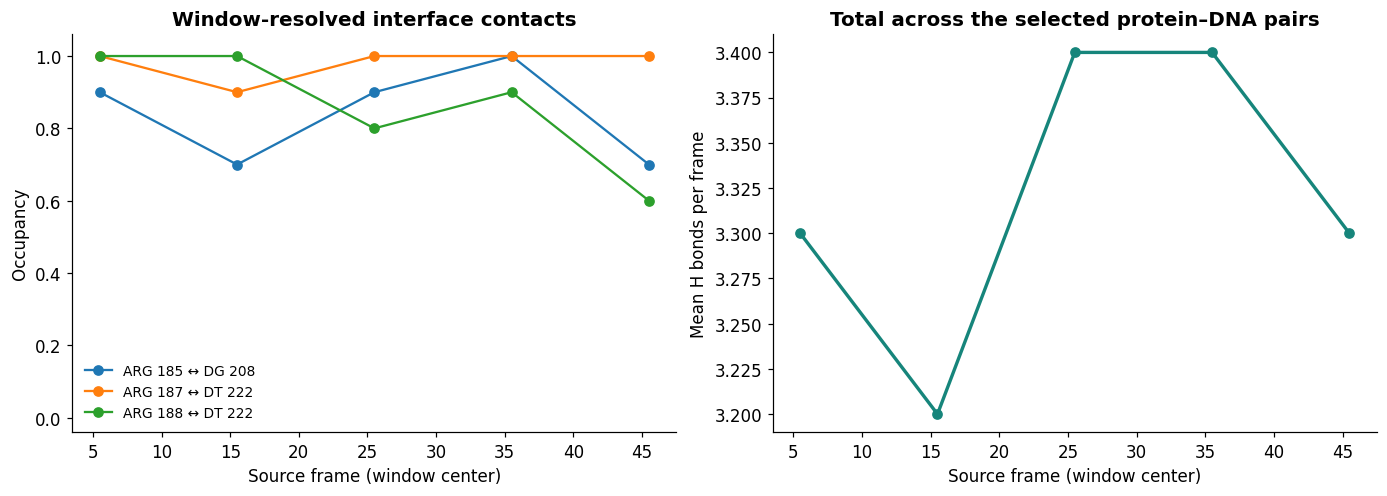

In [21]:
occupancy = interface["features"]["hbond_occupancy"]
centers = window_centers(interface)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.4), layout="constrained")
for row, protein_position in enumerate(protein_positions):
    for column, dna_position in enumerate(dna_positions):
        if mean_occupancy[protein_position, dna_position] > 0:
            axes[0].plot(centers, occupancy[:, protein_position, dna_position], "o-",
                         label=f"{protein_labels[row]} ↔ {dna_labels[column]}")
axes[0].set(xlabel="Source frame (window center)", ylabel="Occupancy",
            title="Window-resolved interface contacts", ylim=(-0.04, 1.06))
axes[0].legend(frameon=False, fontsize=9)
axes[1].plot(centers, interface["features"]["total_interface_hbonds"], "o-", color=TEAL, linewidth=2.2)
axes[1].set(xlabel="Source frame (window center)", ylabel="Mean H bonds per frame",
            title="Total across the selected protein–DNA pairs")
plt.show()

The rectangular heatmaps show each selected protein–DNA pair once. An occupancy near one with
mean count above one indicates a persistent contact that can carry several hydrogen bonds.
The history panel shows how those statistics vary across this excerpt. These geometric contact
measurements support inspection of interface dynamics and depend on the selected atoms and criteria.

## Extra · Radius of gyration and a trajectory summary

CPPTRAJ calculates the mass-weighted radius of gyration of the selected protein atoms, in angstroms.
This describes their spread around the center of mass. We save window means and a single trajectory
mean obtained from the completed window feature. Window means are weighted by their actual frame
counts when combined. [CPPTRAJ radius of gyration](https://amberhub.chpc.utah.edu/radgyr-rog/)

In [22]:
class GyrationFeatures(FeatureExtractor):
    @feature(
        kind="global", scope="window", shape=(), dtype="float64",
        units="angstrom", statistic="mean per-frame mass-weighted radius of gyration",
    )
    def mean_rg(self, ctx: ExtractionContext):
        """Average CPPTRAJ radius-of-gyration values within each window."""
        files = cpptraj_files(ctx, ctx.frame_ids, """
radgyr Size {mask} mass nomax out "{directory}/rg.dat" prec 18.10
run
""")
        return window_means(frame_values(files["rg.dat"], ctx.frame_ids), ctx.windows)

    @feature(
        kind="global", scope="trajectory", shape=(), dtype="float64",
        units="angstrom", statistic="frame-weighted mean of window mean_rg values",
        requires=("mean_rg",),
    )
    def trajectory_mean_rg(self, ctx: ExtractionContext):
        """Combine saved window means with their actual frame counts."""
        weighted_sum = 0.0
        start = 0
        for means in ctx.dependencies["mean_rg"].block_iter(step=128):
            counts = [len(window) for window in ctx.windows[start:start + len(means)]]
            weighted_sum += np.dot(means, counts)
            start += len(means)
        return np.asarray(weighted_sum / len(ctx.frame_ids), dtype="float64")

In [23]:
gyration_path = GyrationFeatures().featurize(**protein_inputs, output_path=output_dir / "protein_gyration.zip")
gyration = load_archive(gyration_path)
trajectory_rg = float(gyration["features"]["trajectory_mean_rg"][0])
print(f"Mean protein radius of gyration over selected frames · {trajectory_rg:.3f} Å")

Mean protein radius of gyration over selected frames · 16.965 Å


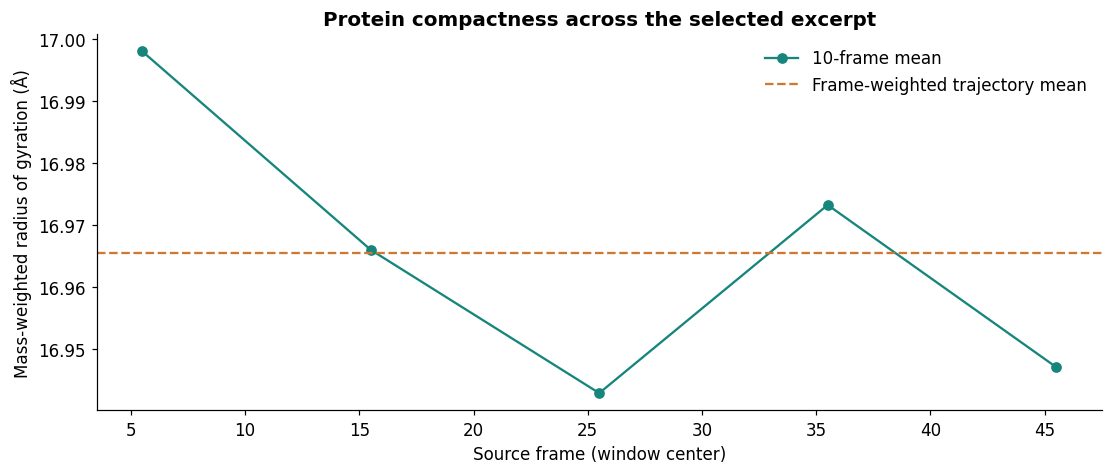

In [24]:
fig, ax = plt.subplots(layout="constrained")
ax.plot(window_centers(gyration), gyration["features"]["mean_rg"], "o-", color=TEAL,
        label=f"{WINDOW_SIZE}-frame mean")
ax.axhline(trajectory_rg, color=ORANGE, linestyle="--", label="Frame-weighted trajectory mean")
ax.set(xlabel="Source frame (window center)", ylabel="Mass-weighted radius of gyration (Å)",
       title="Protein compactness across the selected excerpt")
ax.legend(frameon=False)
plt.show()

## The saved result can be reopened and shared

Every archive includes the ordered feature declarations, selected residue and atom identities,
source-frame IDs, windows, units, and schema markers. The next cell reads the protein–DNA archive
and retrieves a few rows at a time, as a later analysis would do.

Array positions start at zero. The saved molecule, residue, atom, and source-frame IDs start at one.
The source files remain external provenance references, so retain them for reproducing extraction.

In [25]:
with ArrayStorage(interface_path, mode="r") as archive:
    print("Schema", archive.get_attr("schema_name"), "version", archive.get_attr("schema_version"))
    print("Produced with SAWNERGY", archive.get_attr("producer_version"))
    print("Residue identities", archive.read("residue_ids").tolist())
    print("Selected source frames", archive.read("frame_ids")[[0, -1]].tolist())
    print("Window offsets", archive.read("window_offsets").tolist())
    for declaration in archive.get_attr("features"):
        block = declaration["block"]
        print(declaration["name"], "|", declaration["units"], "|", declaration["statistic"])
        first_batch = next(archive.block_iter(block, step=2))
        print("  First read batch shape", first_batch.shape)

Schema traj_features version 1
Produced with SAWNERGY 1.1.6
Residue identities [[1, 185], [1, 187], [1, 188], [2, 208], [3, 222]]
Selected source frames [1, 50]
Window offsets [0, 10, 20, 30, 40, 50]
mean_hbonds | 1 | mean protein-DNA hydrogen-bond count per residue pair
  First read batch shape (2, 5, 5)
hbond_occupancy | 1 | fraction of frames with any protein-DNA hydrogen bond per residue pair
  First read batch shape (2, 5, 5)
total_interface_hbonds | 1 | mean total hydrogen-bond count across selected protein-DNA pairs
  First read batch shape (2,)


## What this extension makes available to the lab

- Choose complete residues across molecules and calculate several measurements through one interface.
- Keep global measurements, residue-pair matrices, window results, and whole-excerpt summaries together
  with their meanings and identities.
- Add a feature by subclassing, or derive it from a completed feature through `requires`.
- Reopen the compressed results in a later notebook and read selected rows or batches.

The feature methods in this notebook are working examples that you can adapt. The current extraction
workflow uses CPPTRAJ to prepare topology identities and frames. Support for preparing inputs without
an executable is a planned extension.

For a lab discussion, compare a different protein–DNA residue selection or a different window size
while keeping the physical definition fixed. The 50-frame default is a short demonstration excerpt.
Longer-range behavior requires examining the corresponding part of the simulation.

The user guide contains the underlying examples and parameter descriptions. [SAWNERGY documentation](https://ymishchyriak.com/docs/SAWNERGY-DOCS)

In [26]:
archive_paths = [rmsd_path, rmsd_frame_path, rmsf_path, energy_path, hbond_path, interface_path, gyration_path]
for path in archive_paths:
    path = Path(path)
    print(f"{path.name:<34} {path.stat().st_size / 1024:>7.1f} KiB")
print(f"Notebook execution elapsed time · {perf_counter() - notebook_started:.2f} s")

protein_rmsd_windows.zip              19.7 KiB
protein_rmsd_frames.zip               20.0 KiB
protein_rmsf.zip                      21.0 KiB
interface_energies.zip                24.0 KiB
protein_hbond_counts.zip              19.5 KiB
protein_dna_hbonds.zip                24.9 KiB
protein_gyration.zip                  21.8 KiB
Notebook execution elapsed time · 5.99 s
